# Imports

In [1]:
import os
import sys
import gc
import numpy as np
import scipy.io
import scipy.ndimage as ndi
import matplotlib.pyplot as plt
from pathlib import Path
from skimage.morphology import medial_axis, thin
from skimage.measure import label, regionprops
from matplotlib.patches import Ellipse

# --- BOOTSTRAP: Find config and register root ---
cwd = Path.cwd()
root_path = next((p for p in [cwd] + list(cwd.parents) if (p / "config.py").exists()), None)
if root_path and str(root_path) not in sys.path:
    sys.path.insert(0, str(root_path))

import config 
import extractcellfeatures # importable because config registered the legacy scripts dir

# --- 1. FILE DISCOVERY ---
# Uses the helper function from config to find .mat files and filter results
matfilepaths = config.get_mat_files()
print(f"Total cells found: {len(matfilepaths)}")

# --- 2. OUTPUT SETUP ---
# Creates 'root/results/topo_feats' if it doesn't exist
BASE_OUT_DIR = config.get_output_dir("topo_feats")

# --- 3. GLOBAL SETTINGS ---
# Use config.TDA_RES whenever you need the resolution value
print(f"Running extraction at resolution: {config.TDA_RES}")
TDA_RES = config.TDA_RES

Total cells found: 399
Running extraction at resolution: 100


# Helper function to process 1 cell from .mat file to segmented image, RDF, ADF and save to .csv

In [2]:
def process_single_cell(mat_path, px2um=0.16): #px2um is pixel to micrometers
    """Loads and transforms a single cell .mat file."""
    # Load and Metadata
    mat_data = scipy.io.loadmat(mat_path)
    if 'bin_mask' not in mat_data: return None
    bin_img = mat_data['bin_mask'] #bin_mask is the key from matlab file
    
    # Precise Crop & Pad (25px buffer)
    coords = np.argwhere(bin_img)
    if coords.size == 0: return None

    # Crop to bounding box of the cell
    y_min, x_min = coords.min(axis=0); y_max, x_max = coords.max(axis=0)
    cropped = bin_img[y_min:y_max+1, x_min:x_max+1]

    # Padding
    bin_mask = np.pad(cropped, pad_width=25, mode='constant', constant_values=0)
    
    # Medial Axis
    # skel = 1D skeleton of the cell, dist_transform = distance from each pixel to nearest background pixel, dist_on_skel = distance values only on the skeleton pixels (0 elsewhere)
    skel, dist_transform = medial_axis(bin_mask, return_distance=True)
    dist_on_skel = dist_transform * thin(bin_mask)
    
    # Feature Extractor (using custom module)
    # This gathers all the (Y, X) coordinates where the cell exists and converts them into a list of points (PIF). It feeds this list into a custom module (extractcellfeatures), asks it to calculate basic properties, shape properties, and geometric fits, and handles any crashes
    y_idx, x_idx = np.where(bin_img == 1)
    PIF = np.column_stack((y_idx, x_idx)).tolist()
    try:
        extractor = extractcellfeatures.ExtractFeatures(PIF)
        extractor.basic_props(3)
        extractor.shape_props()
        extractor.cell_centre_fit()
    except:
        return None
    

    # Alignment: Rotate to Horizontal
    props = regionprops(label(bin_mask))[0]
    angle_deg = np.degrees(props.orientation)
    rotated_mask = ndi.rotate(bin_mask, -angle_deg, order=0)
    
    # Shift center of the image to be cell's centroid
    cy, cx = ndi.center_of_mass(rotated_mask)
    y_r, x_r = np.where(rotated_mask == 1)
    dx, dy = x_r - cx, y_r - cy
    
    # Radial (RDF)
    dist_um = np.sqrt(dx**2 + dy**2) * px2um
    rdf_counts, rdf_bins = np.histogram(dist_um, bins=TDA_RES, density=True)
    
    # Angular (ADF) - FIXING THE BREAK
    angles_rad = np.mod(np.arctan2(dy, dx), 2 * np.pi) 
    adf_counts, adf_bins = np.histogram(angles_rad, bins=np.linspace(0, 2*np.pi, TDA_RES+1), density=True)
    adf_x = (adf_bins[:-1] + adf_bins[1:]) / 2

    # Append first point to end to close the visual loop
    adf_x_closed = np.append(adf_x, adf_x[0] + 2*np.pi)
    adf_counts_closed = np.append(adf_counts, adf_counts[0])

    # Return as dictionary, caller need to look up the data by name
    return {
        "extractor": extractor, "dist_on_skel": dist_on_skel,
        "rotated_mask": rotated_mask, "cx": cx, "cy": cy,
        "rdf": ((rdf_bins[:-1]+rdf_bins[1:])/2, rdf_counts),
        "adf": (adf_x_closed, adf_counts_closed),
        "bin_mask": bin_mask
    }

In [3]:
import math

def create_grid_plot(data_list, plot_type, out_path):
    """Generates a responsive grid plot based on the length of data_list."""
    num_cells = len(data_list)
    if num_cells == 0: return

    # --- Responsive Layout Logic ---
    ncols = 5 if num_cells >= 5 else num_cells
    nrows = math.ceil(num_cells / ncols)
    
    is_polar = (plot_type == 'adf')
    
    # Create the figure
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows), 
                             subplot_kw={'projection': 'polar'} if is_polar else None,
                             squeeze=False) # squeeze=False ensures axes is always a 2D array
    
    plt.suptitle(f"Batch Analysis: {plot_type.upper()} Plots (First {num_cells} Cells)", 
                 fontsize=16, y=1.02)

    for i in range(nrows * ncols):
        row, col = i // ncols, i % ncols
        ax = axes[row, col]
        
        # If we have data for this slot, plot it
        if i < num_cells:
            cell_data = data_list[i]
            ext = cell_data["extractor"]
            
            if plot_type == 'fits':
                ax.imshow(np.transpose(ext.perim_img), cmap='Greys', alpha=0.3)
                c = plt.Circle((ext.ccm_fvector[0], ext.ccm_fvector[1]), ext.ccm_fvector[2], 
                               fill=False, edgecolor='blue', lw=1.5)
                e = Ellipse(xy=(ext.ellipse_fvector[0], ext.ellipse_fvector[1]),
                            width=ext.ellipse_fvector[4], height=ext.ellipse_fvector[3],
                            angle=ext.ellipse_fvector[5]/(2*np.pi)*360, 
                            fill=False, edgecolor='orange', lw=1.5)
                ax.add_patch(c); ax.add_patch(e)
                ax.set_aspect('equal')
                ax.axis('off')

            elif plot_type == 'medial_axis':
                ax.imshow(cell_data["dist_on_skel"], cmap='Spectral')
                ax.contour(cell_data["bin_mask"], [0.5], colors='w', linewidths=0.5)
                ax.axis('off')

            elif plot_type == 'rotated':
                ax.imshow(cell_data["rotated_mask"], cmap='gray_r')
                ax.scatter(cell_data["cx"], cell_data["cy"], color='red', marker='+', s=50)
                ax.axis('off')

            elif plot_type == 'rdf':
                ax.plot(cell_data["rdf"][0], cell_data["rdf"][1], color='purple', lw=1.5)
                ax.fill_between(cell_data["rdf"][0], cell_data["rdf"][1], alpha=0.1, color='purple')
                ax.grid(True, alpha=0.2); ax.set_xlabel('um', fontsize=8)

            elif plot_type == 'adf':
                ax.plot(cell_data["adf"][0], cell_data["adf"][1], color='darkorange', lw=1.5)
                ax.fill_between(cell_data["adf"][0], cell_data["adf"][1], alpha=0.2, color='orange')
                ax.set_yticklabels([]); ax.grid(True, alpha=0.2)

            ax.set_title(f"Cell {i}", fontsize=10)
        
        # If no data (empty slot in the grid), hide the axes
        else:
            ax.axis('off')
            if is_polar:
                ax.grid(False)
                ax.set_xticklabels([])

    plt.tight_layout()
    plt.savefig(out_path, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

Processing 399 cells...
Generating summary grid: medial_axis...


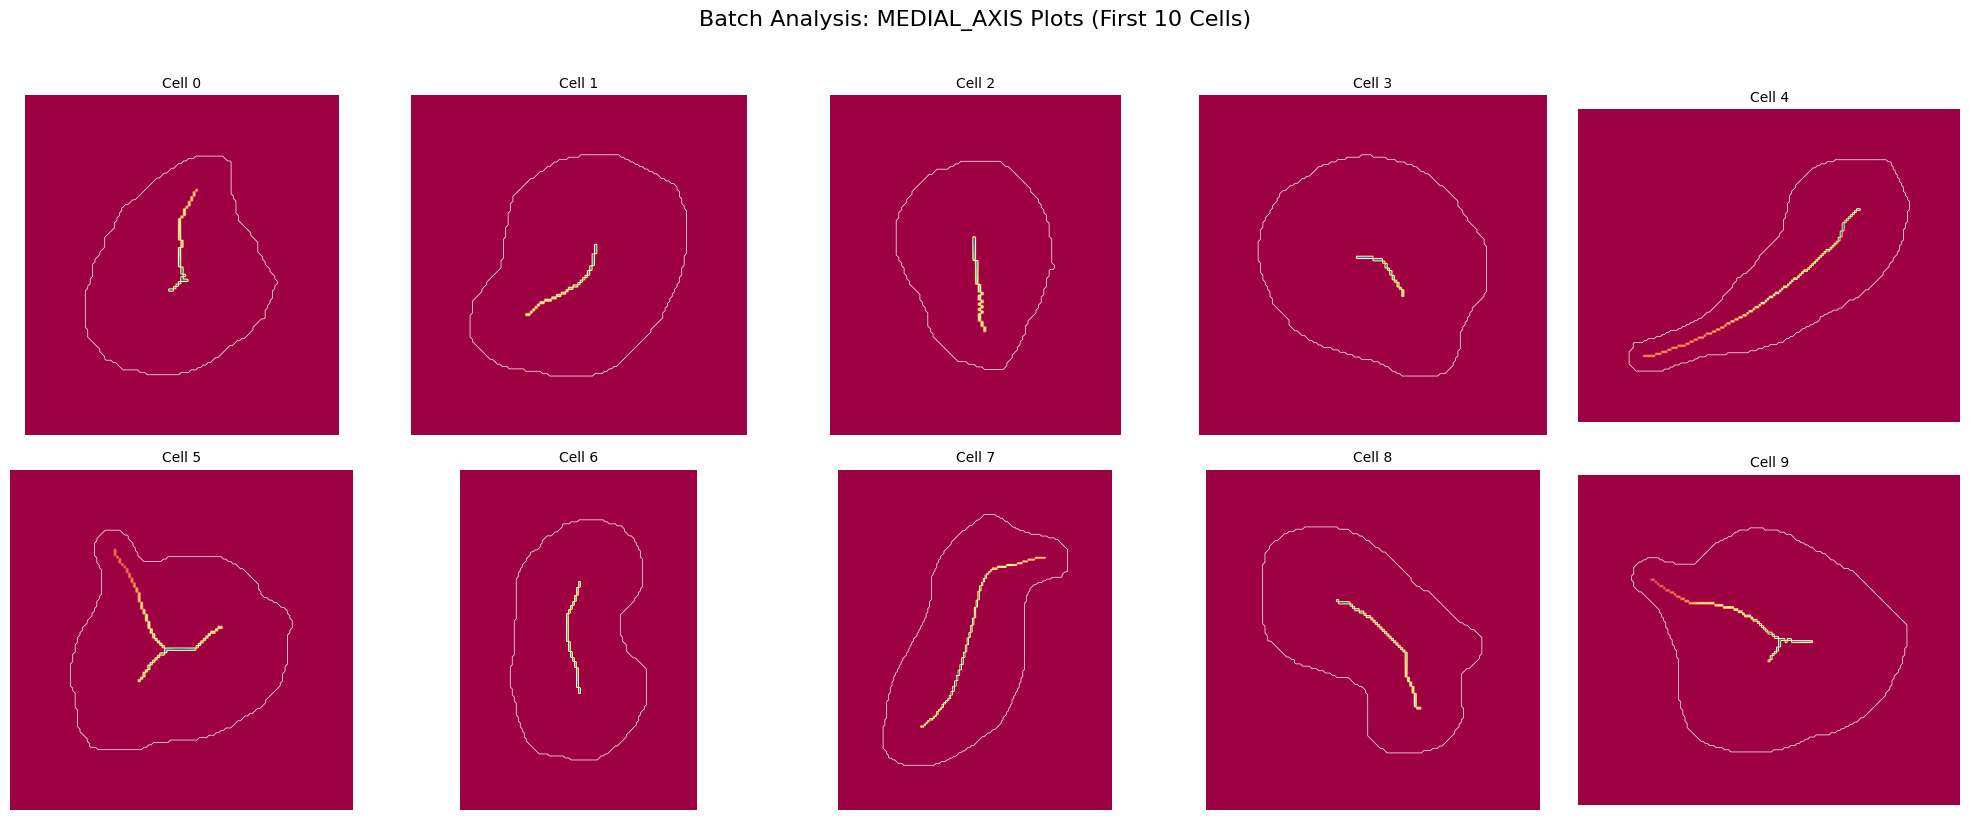

Generating summary grid: rotated...


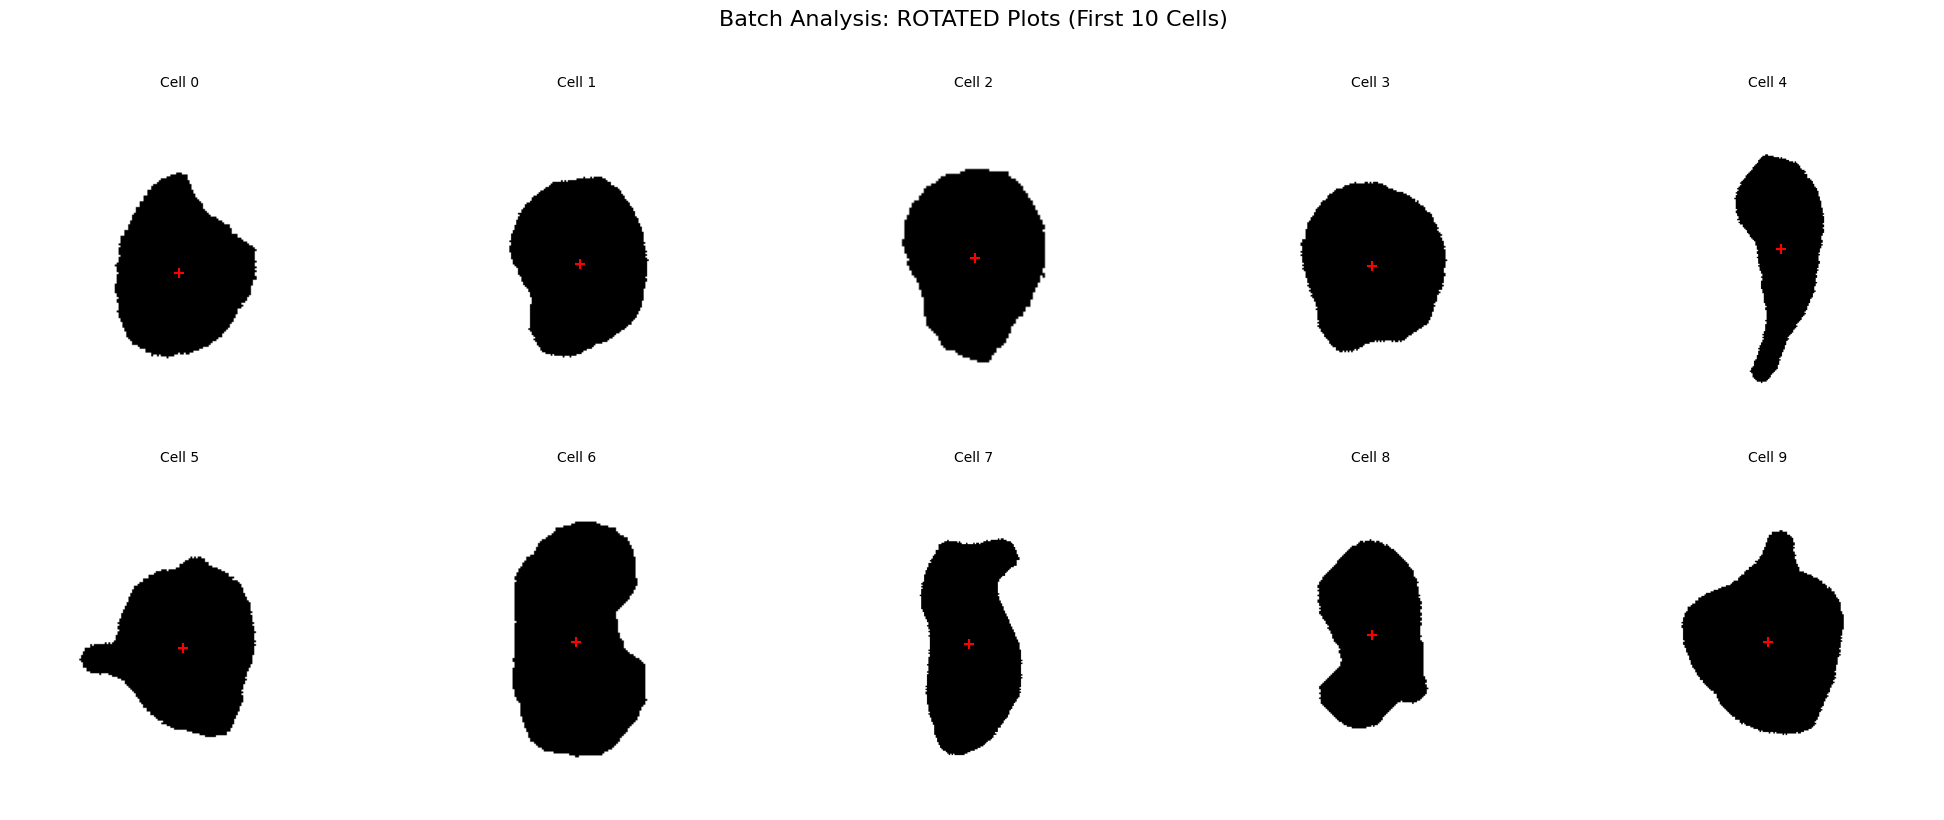

Generating summary grid: rdf...


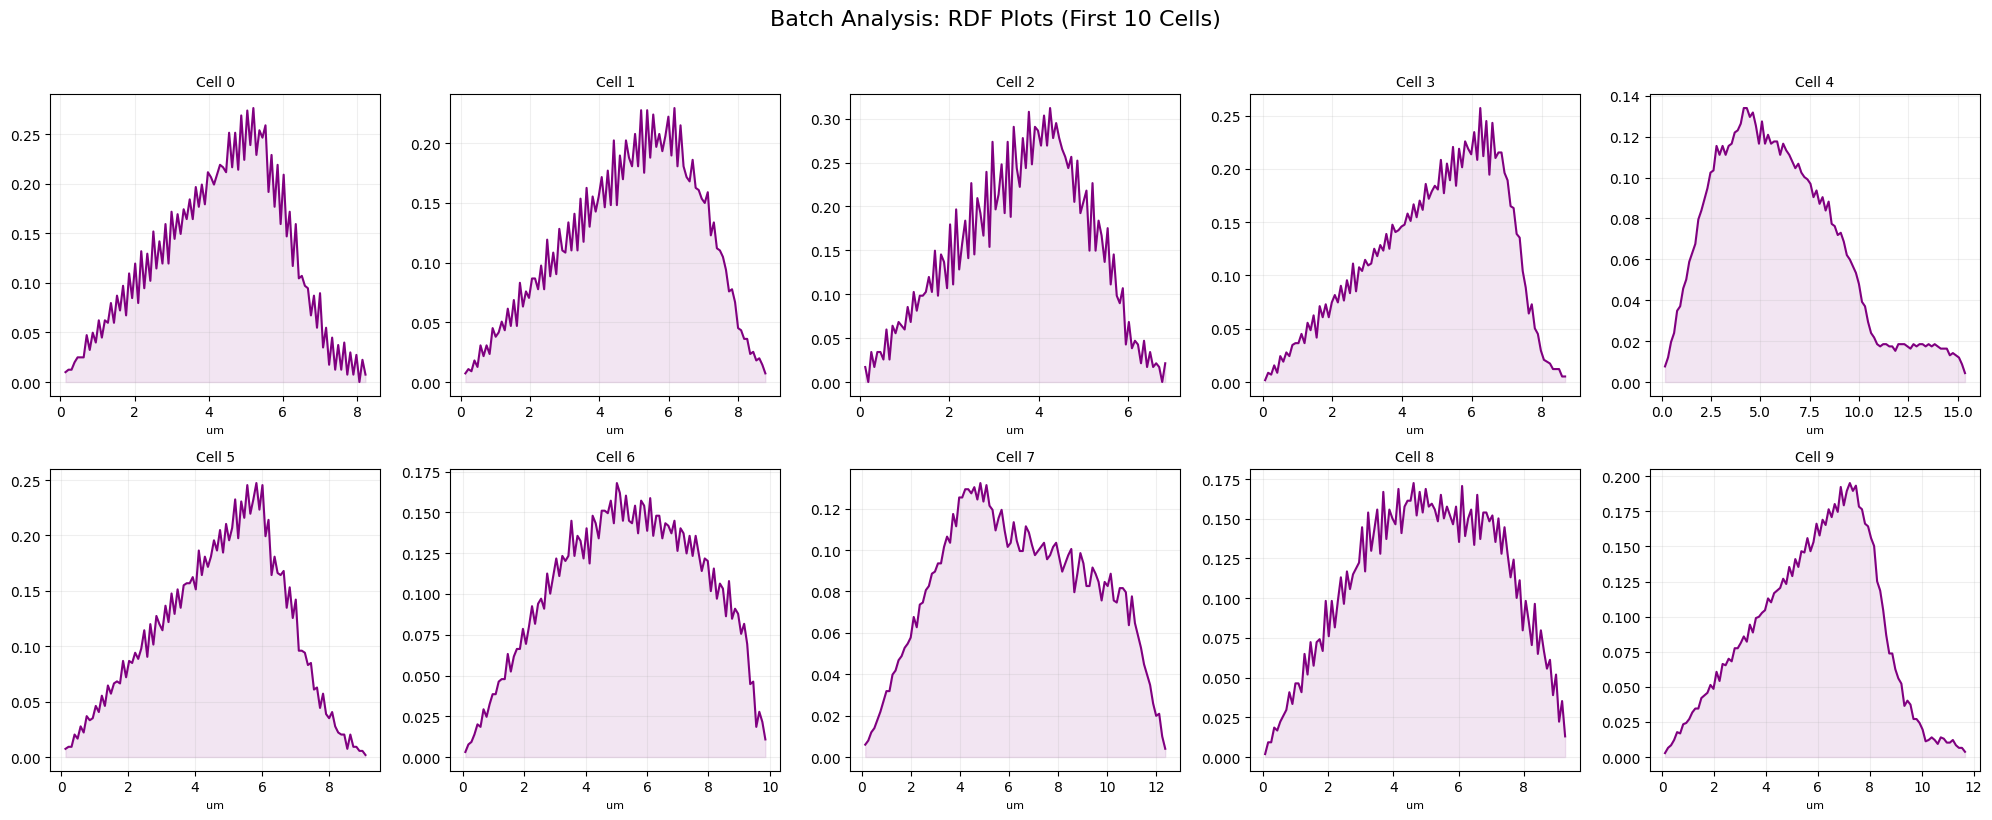

Batch Processing Complete! Each cell folder now contains its specific plots.
Generating summary grid: adf (Cartesian)...


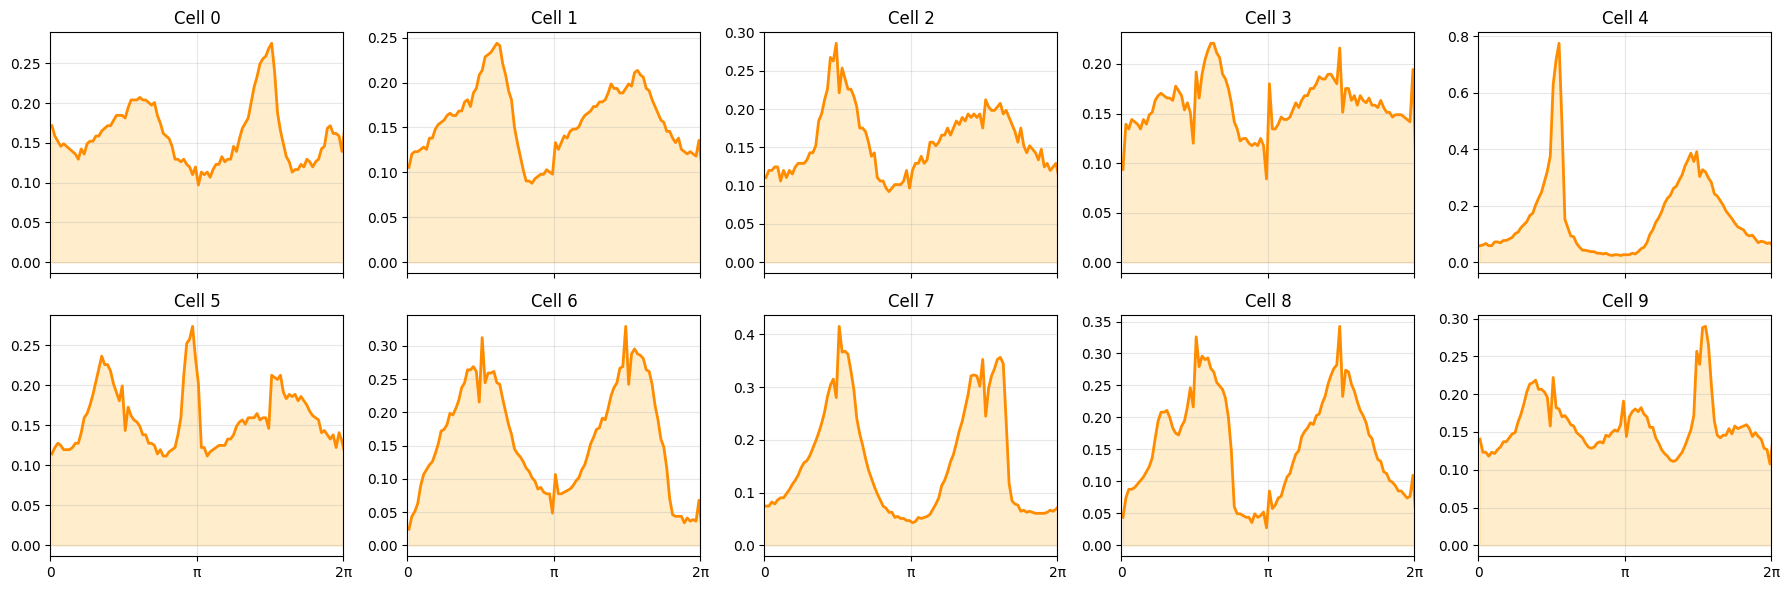

Cartesian ADF batch visualization displayed and saved!


In [4]:
import math
import gc
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Ellipse
from pathlib import Path

# --- Configuration ---
NUM_TO_PROCESS = 399
NUM_TO_VISUALIZE = 10
# Removed 'adf' from this list since we are handling its grid manually at the bottom
PLOT_TYPES = ['medial_axis', 'rotated', 'rdf'] 

processed_data_visuals = []

print(f"Processing {NUM_TO_PROCESS} cells...")

for cID, path in enumerate(matfilepaths[:NUM_TO_PROCESS]):
    cell_data = process_single_cell(path)
    if cell_data is None: continue
    
    # 1. Setup Cell Folder
    cell_folder = Path(BASE_OUT_DIR) / f"cID_{cID}"
    cell_folder.mkdir(parents=True, exist_ok=True)
    
    # 2. Save Data Files
    np.save(cell_folder / 'MedialAxis.npy', cell_data["dist_on_skel"])

    # Stack the X and Y arrays into a single 2D array
    adf_raw_data = np.array([cell_data["adf"][0], cell_data["adf"][1]])
    rdf_raw_data = np.array([cell_data["rdf"][0], cell_data["rdf"][1]])

    # Save them directly to the current cell's folder
    np.save(cell_folder / f"cell_{cID}_adf_raw.npy", adf_raw_data)
    np.save(cell_folder / f"cell_{cID}_rdf_raw.npy", rdf_raw_data)

    # 3. Save Individual Plots (Rotated, RDF, ADF)
    
    # --- Individual ROTATED Save ---
    fig_rot, ax_rot = plt.subplots(figsize=(4, 4))
    ax_rot.imshow(cell_data["rotated_mask"], cmap='gray_r')
    ax_rot.scatter(cell_data["cx"], cell_data["cy"], color='red', marker='+', s=100)
    ax_rot.set_title(f"Cell {cID} - Aligned")
    ax_rot.axis('off')
    fig_rot.savefig(cell_folder / f"cell_{cID}_rotated.png", dpi=100)
    plt.close(fig_rot)

    # --- Individual RDF Save ---
    fig_rdf, ax_rdf = plt.subplots(figsize=(5, 4))
    ax_rdf.plot(cell_data["rdf"][0], cell_data["rdf"][1], color='purple', lw=2)
    ax_rdf.fill_between(cell_data["rdf"][0], cell_data["rdf"][1], alpha=0.1, color='purple')
    ax_rdf.set_title(f"Cell {cID} - Radial Distribution")
    ax_rdf.set_xlabel('um')
    ax_rdf.grid(True, alpha=0.3)
    fig_rdf.savefig(cell_folder / f"cell_{cID}_rdf.png", dpi=100)
    plt.close(fig_rdf)

    # --- Individual ADF Save (Cartesian Plane) ---
    fig_adf, ax_adf = plt.subplots(figsize=(6, 4))
    ax_adf.plot(cell_data["adf"][0], cell_data["adf"][1], color='darkorange', lw=2)
    ax_adf.fill_between(cell_data["adf"][0], cell_data["adf"][1], alpha=0.2, color='orange')
    ax_adf.set_title(f"Cell {cID} - Angular Distribution")
    ax_adf.set_xlabel('Angle (radians)')
    ax_adf.set_ylabel('Distribution')
    ax_adf.grid(True, alpha=0.3)
    ax_adf.set_xlim(0, 2 * np.pi)
    ax_adf.set_xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi])
    ax_adf.set_xticklabels(['0', 'π/2', 'π', '3π/2', '2π'])
    
    # Save the individual Cartesian figure
    fig_adf.savefig(cell_folder / f"cell_{cID}_adf.png", dpi=100, bbox_inches='tight')
    plt.close(fig_adf)

    # 4. Store for batch visualization (Grid plots)
    if cID < NUM_TO_VISUALIZE:
        processed_data_visuals.append(cell_data)
        
    # Periodic garbage collection for stability
    if cID % 10 == 0: gc.collect()

# 5. Generate the Grid plots for the top cells
for p_type in PLOT_TYPES:
    filename = f"Grid_{p_type.upper()}_First_{len(processed_data_visuals)}_Cells.png"
    out_path = Path(BASE_OUT_DIR) / filename
    print(f"Generating summary grid: {p_type}...")
    create_grid_plot(processed_data_visuals, p_type, out_path)

print("Batch Processing Complete! Each cell folder now contains its specific plots.")

# 6. Custom Batch Grid Visualization for ADF (Cartesian)
print("Generating summary grid: adf (Cartesian)...")

num_cells = min(len(processed_data_visuals), 10)
fig_grid, axes = plt.subplots(nrows=2, ncols=5, figsize=(18, 6), sharex=True)
axes = axes.flatten()

for i in range(num_cells):
    cell_data = processed_data_visuals[i]
    angles = cell_data["adf"][0]
    values = cell_data["adf"][1]
    
    ax_grid = axes[i]
    ax_grid.plot(angles, values, color='darkorange', lw=2)
    ax_grid.fill_between(angles, values, alpha=0.2, color='orange')
    ax_grid.set_title(f"Cell {i}")
    ax_grid.grid(True, alpha=0.3)
    ax_grid.set_xlim(0, 2 * np.pi)
    
    # Simpler ticks for the small grid view
    ax_grid.set_xticks([0, np.pi, 2 * np.pi])
    ax_grid.set_xticklabels(['0', 'π', '2π'])

# Clean up any empty subplots in the grid if you have fewer than 10 cells
for j in range(num_cells, len(axes)):
    fig_grid.delaxes(axes[j])

# Automatically adjust grid spacing
fig_grid.tight_layout()

# Save the grid plot to the main directory

grid_save_path = Path(BASE_OUT_DIR) / f"Grid_ADF_First_{num_cells}_Cells.png"
fig_grid.savefig(grid_save_path, dpi=150, bbox_inches='tight')

# Display the grid in the notebook
plt.show()

print("Cartesian ADF batch visualization displayed and saved!")